# Ej. 1 · Entrenamiento y ejecución completos (3,5 puntos)

**Objetivo (enunciado):** completar `execution_lab.ipynb` hasta lograr un entrenamiento y una ejecución completos, con los
elementos de un entorno de RL, el orden de interacción correcto y el entrenamiento en el orden que exige el algoritmo.

### Bloques modificados respecto a `execution_lab.ipynb`

| Bloque del LAB | Cambio | Motivo | Decisión |
|---|---|---|---|
| Celda 7 · `BestExecutionEnv` | 13 funciones completadas, en `common/env.py` | El enunciado permite estructurar el código en `.py`; el notebook 00 las presenta | D-0.3 |
| Celda 3 · `DDQNAgent` | Portado a PyTorch con la misma interfaz | TF 2.15 no instala en Python ≥ 3.12 y es más lento | D-0.1 |
| Celda 9 · `TWAP` | `TWAPAgent`: compra si V ≥ T | Benchmark determinista | D-1.4 |
| Celda 12 · parámetros | Valores elegidos (abajo) | El ej. 1 no exige motivarlos | — |
| Celda 16 · llenado del buffer | 25 episodios aleatorios en lugar de `buffer_size` pasos | Recomendación de clase: llenarlo solo en parte | D-1.1 |
| Celda 18 · bucle | `protocol.train`, mismo orden de llamadas | Reutilizable en los ejercicios 2-4 | D-0.3 |
| Celda 20 · evaluación | Greedy en train y en test | Train para las figuras; test como en el LAB | — |

In [1]:
import os, sys
from pathlib import Path
ROOT = Path.cwd() if (Path.cwd() / "notebooks" / "common").is_dir() else Path.cwd().parent
sys.path.insert(0, str(ROOT / "notebooks"))
import numpy as np, pandas as pd, matplotlib.pyplot as plt, torch
from common import data as dt, rewards as rw, exploration as ex, protocol as pr, plots as pl
from common.env import BestExecutionEnv
from common.agents import DDQNAgent, TWAPAgent
torch.set_num_threads(1)
pd.set_option("display.precision", 3)
%matplotlib inline

In [2]:
ASSET = "REP"                      # D-0.2
DATA = dt.load(ASSET)
train = DATA["train"]
GRID = pr.make_grid(train, n_days=3, seed=0)   # rejilla fija de evaluación (D-0.3)
print(dt.summary(DATA)); print(len(GRID), "episodios de evaluación")

{'train': {'dias': 60, 'filas_por_dia': [3177, 3178, 3179]}, 'val': {'dias': 30, 'filas_por_dia': [3179, 3180, 3181]}, 'test': {'dias': 30, 'filas_por_dia': [3179, 3180, 3181]}}
27 episodios de evaluación


## 1. Parámetros

Configuración del ejercicio 1, con la recompensa por defecto del LAB (slippage frente al VWAP del episodio, sin penalización terminal). En este ejercicio se comprueba que todo el circuito funciona; el objetivo de seguimiento TWAP se introduce en el ejercicio 2.

In [3]:
# Agent params
epsilon, min_epsilon = 1.0, 0.02
gamma = 0.99
alpha = 1e-3
buffer_size = 50_000
batch_size = 64
hidden_neurons = 64
# Training params
nepisodes = 4000
epsilon_decay = (epsilon - min_epsilon) / (0.5 * nepisodes)   # llega al mínimo a mitad de entrenamiento
learn_after = batch_size
update_target_after = 10 * learn_after
SEED = 0
fill_episodes = 25
force_first_buy = True             # conserva la compra inicial del agente del LAB
OBS_MODE = "TV"
CONFIG = dict(asset=ASSET, reward="default", terminal_reward=0.0, obs_mode=OBS_MODE,
              look_back=60, bins_range=[400, 600], pct_range=[0.075, 0.125],
              gamma=gamma, alpha=alpha, epsilon=epsilon, min_epsilon=min_epsilon,
              epsilon_decay=epsilon_decay, buffer_size=buffer_size, batch_size=batch_size,
              hidden_neurons=hidden_neurons, nepisodes=nepisodes, learn_after=learn_after,
              update_target_after=update_target_after, fill_episodes=fill_episodes,
              force_first_buy=force_first_buy, seed=SEED, grid_seed=0, grid_days=3,
              torch_threads=torch.get_num_threads())

In [4]:
from types import SimpleNamespace

# Contrato del reward original: esperar = 0; comprar bajo VWAP = positivo; done = 0.
example = SimpleNamespace(episode_vwap=100.0, vol_care=50, exec_vol=25)
reward = rw.Default()
assert reward.step(example, price=99.0, vol=0) == 0.0
assert np.isclose(reward.step(example, price=99.0, vol=1), 0.01)
assert reward.done(example) == 0.0
print("Reward LAB: esperar = 0; comprar a 99 con VWAP 100 = 0.01; terminal = 0")

Reward LAB: esperar = 0; comprar a 99 con VWAP 100 = 0.01; terminal = 0


## 2. Entorno, agente y llenado del buffer

In [5]:
pr.set_seeds(SEED)
env = BestExecutionEnv(train, look_back=60, reward=rw.Default(), seed=SEED, obs_mode=OBS_MODE)
agent = DDQNAgent(env, gamma=gamma, epsilon=epsilon, alpha=alpha, batch_size=batch_size,
                  buffer_size=buffer_size, hidden_neurons=hidden_neurons, seed=SEED,
                  force_first_buy=force_first_buy)
steps = pr.fill_buffer(agent, env, n_episodes=fill_episodes)
print(f"buffer: {len(agent.buffer)} experiencias ({steps} pasos aleatorios)")

buffer: 12202 experiencias (12202 pasos aleatorios)


## 3. Entrenamiento

Episode 25: steps 491, rew -0.012, mse 0.0000, eps 0.99, 1s


Episode 50: steps 427, rew -0.017, mse 0.0000, eps 0.98, 1s


Episode 75: steps 422, rew -0.011, mse 0.0000, eps 0.96, 2s


Episode 100: steps 404, rew 0.005, mse 0.0000, eps 0.95, 3s


Episode 125: steps 393, rew -0.002, mse 0.0000, eps 0.94, 4s


Episode 150: steps 374, rew -0.012, mse 0.0000, eps 0.93, 4s


... (150 outputs left out)

Episode 3925: steps 113, rew -0.026, mse 0.0000, eps 0.02, 93s


Episode 3950: steps 133, rew -0.010, mse 0.0000, eps 0.02, 94s


Episode 3975: steps 118, rew -0.012, mse 0.0000, eps 0.02, 94s


Episode 4000: steps 124, rew 0.003, mse 0.0000, eps 0.02, 95s


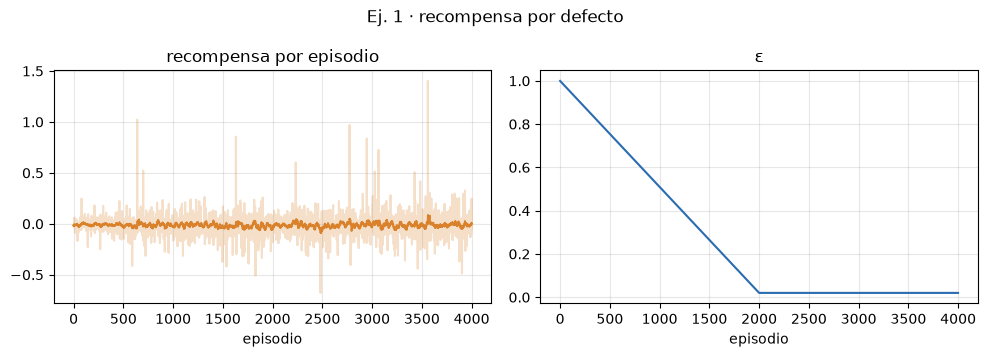

In [6]:
ep, ev = pr.train(agent, env, nepisodes, ex.LinearDecay(epsilon, min_epsilon, epsilon_decay),
                  learn_after=learn_after, update_target_after=update_target_after, log_every=25)
pr.save_df(ep, "ej1_train")
pl.plot_training(ep, title="Ej. 1 · recompensa por defecto", save="ej1_training");

## 4. Ejecución greedy

In [7]:
res = pr.evaluate(agent, train, GRID, reward=rw.Default(), obs_mode=OBS_MODE)
pr.save_df(res, "ej1_eval_train")
# Benchmark calculado ahora sobre exactamente los mismos episodios.
res_twap = pr.evaluate(TWAPAgent(), train, GRID, reward=rw.Default(), obs_mode=OBS_MODE,
                       with_twap=False)
# Evaluación descriptiva en test, una vez fijada la configuración con train.
GRID_TEST = pr.make_grid(DATA["test"], n_days=3, seed=0)
res_test = pr.evaluate(agent, DATA["test"], GRID_TEST, reward=rw.Default(), obs_mode=OBS_MODE)
pr.save_df(res_test, "ej1_eval_test")
import hashlib
CONFIG["source_sha256"] = {
    name: hashlib.sha256((ROOT / "notebooks" / "common" / f"{name}.py").read_bytes()).hexdigest()
    for name in ("env", "rewards", "agents", "protocol", "exploration", "data")
}
pr.save_json(CONFIG, "ej1_config")
agent.save(pr.MODELS / "ej1_ddqn.pt", config=CONFIG)
pd.DataFrame({"DDQN train": pr.summarize(res),
              "TWAP train": pr.summarize(res_twap),
              "DDQN test": pr.summarize(res_test)})

,DDQN train,TWAP train,DDQN test
completed_mean,1.000,1.000,1.000
completed_std,0.000,0.000,0.000
max_err_mean,44.371,0.900,44.371
max_err_std,11.429,0.021,11.429
mean_err_mean,22.343,0.437,22.343
mean_err_std,5.636,0.017,5.636
n_buys_mean,49.889,49.889,49.889
n_buys_std,13.429,13.429,13.429
pending_mean,0.000,0.000,0.000
pending_std,0.000,0.000,0.000


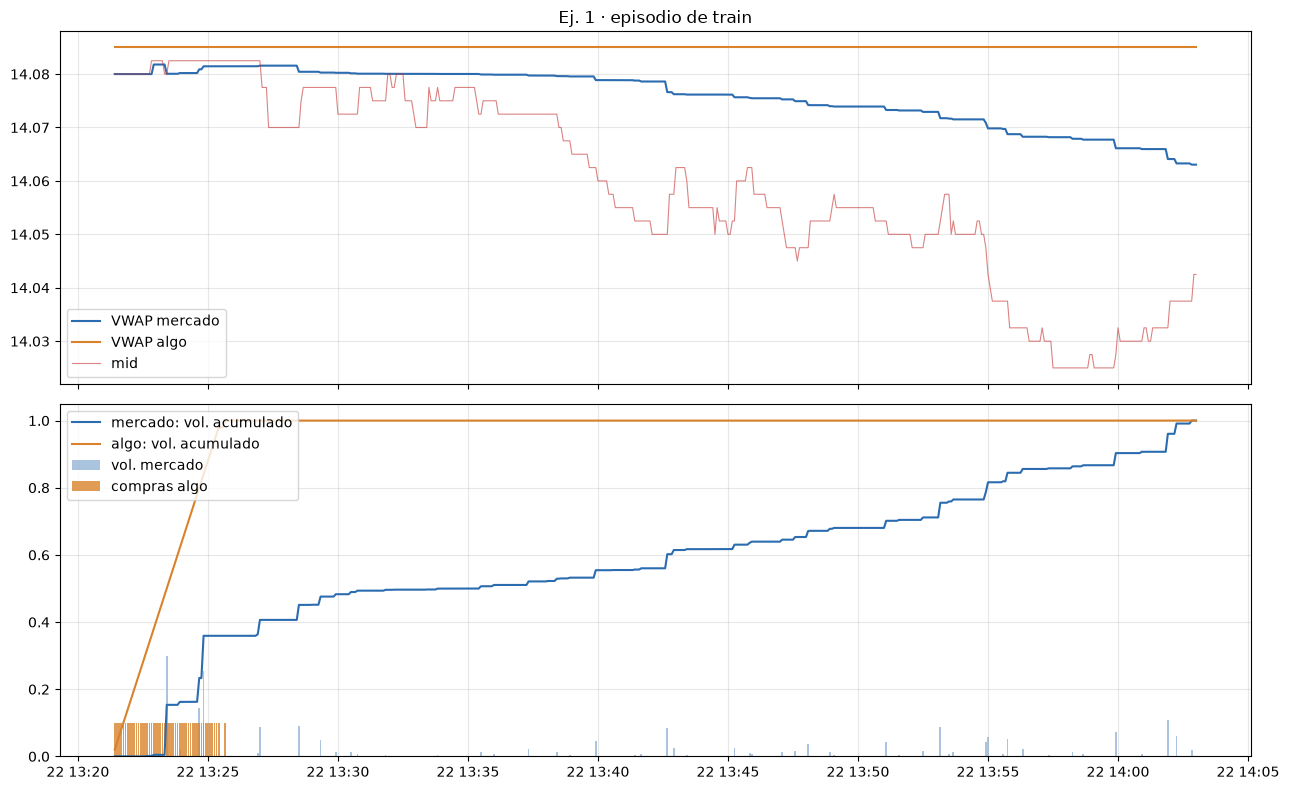

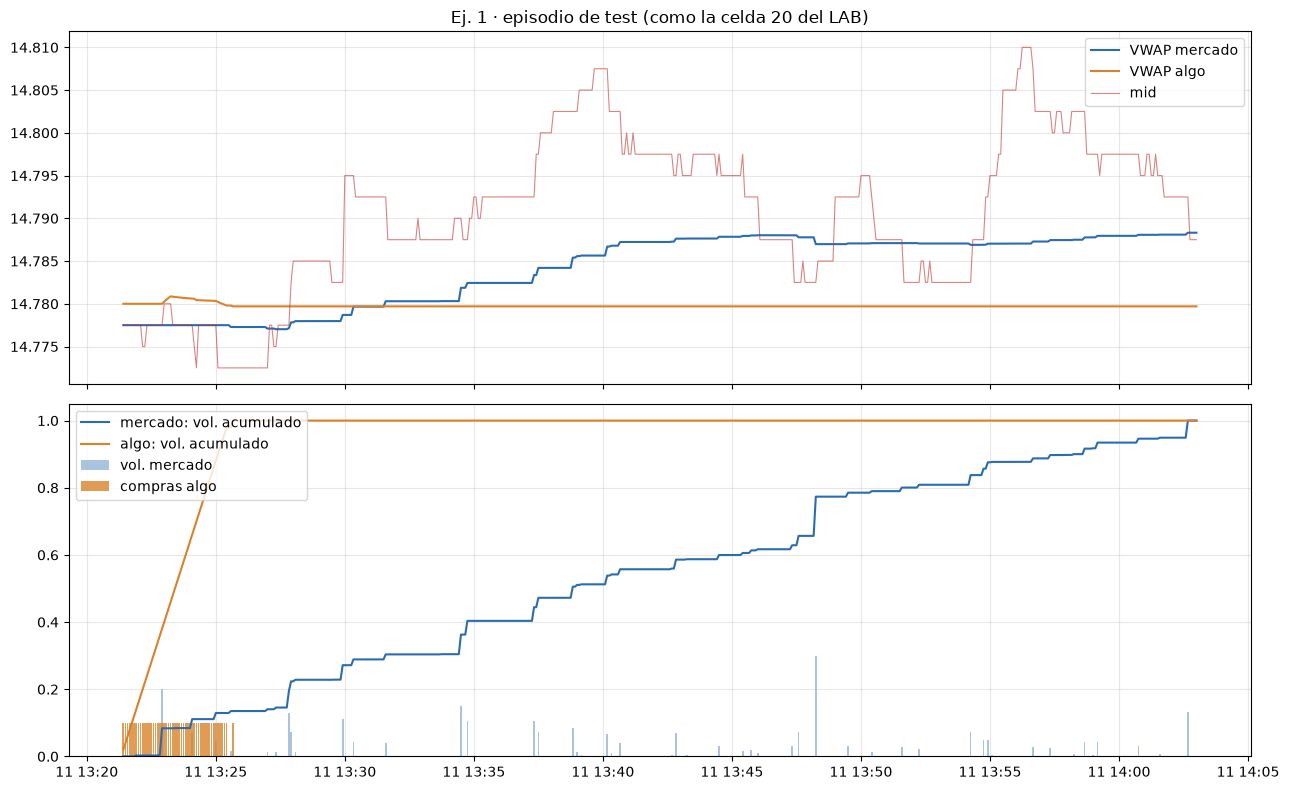

In [8]:
env_tr = BestExecutionEnv(train, seed=1, reward=rw.Default(), obs_mode=OBS_MODE)
agent.env = env_tr; agent.set_trainable(False)
pr.run_episode(env_tr, agent, GRID[4])
pl.plot_results(env_tr, title="Ej. 1 · episodio de train", save="ej1_episodio_train");

env_te = BestExecutionEnv(DATA["test"], seed=1, reward=rw.Default(), obs_mode=OBS_MODE)
agent.env = env_te
pr.run_episode(env_te, agent, GRID_TEST[4])
pl.plot_results(env_te, title="Ej. 1 · episodio de test (como la celda 20 del LAB)", save="ej1_episodio_test");

## 5. Conclusión

El circuito completo funciona: generación de episodios, interacción, buffer, aprendizaje Double DQN con red objetivo y
ejecución greedy. Con la recompensa por defecto el agente **no** tiene motivo para repartir las compras: premia comprar por
debajo del VWAP de todo el episodio, que no puede anticipar con [T, V]. Por eso el ej. 2 cambia la recompensa.